In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Rescaling,Dense,Dropout,Flatten,Conv2D,MaxPooling2D
from tensorflow.keras.callbacks import EarlyStopping

In [31]:
train_dir=r"C:\Users\usaan\Downloads\seg_train\seg_train"
test_dir=r"C:\Users\usaan\Downloads\seg_test\seg_test"
pred_dir=r"C:\Users\usaan\Downloads\seg_pred\seg_pred"

In [59]:
X=['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [3]:
from tensorflow.keras.utils import image_dataset_from_directory

In [4]:
import os
from PIL import Image

1000.jpg: 150x150


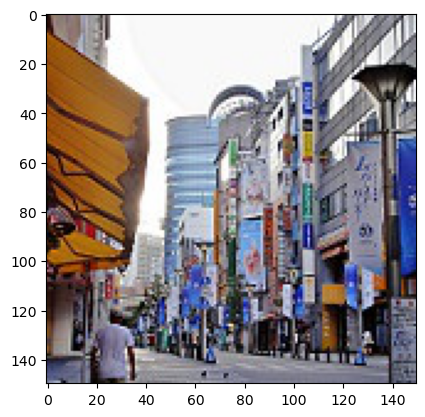

10015.jpg: 150x150


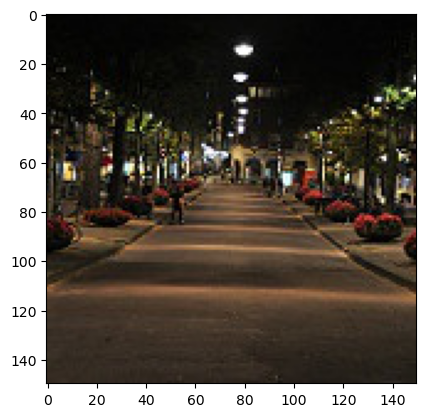

10019.jpg: 150x150


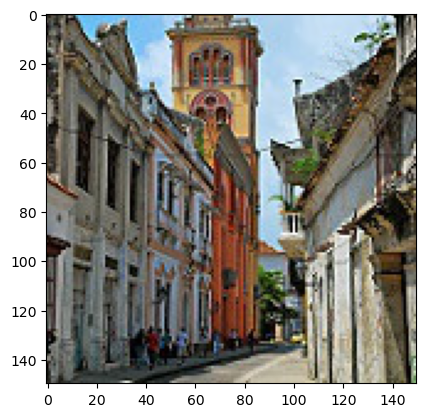

10022.jpg: 150x150


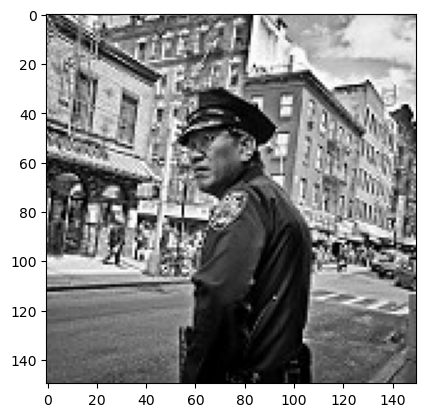

10036.jpg: 150x150


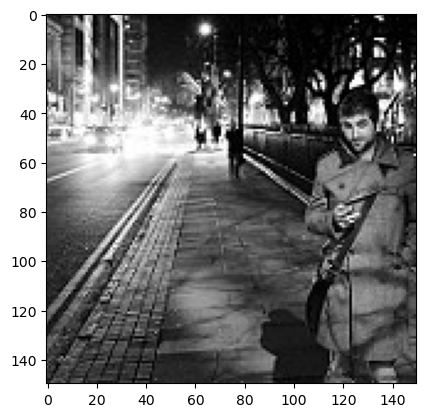

10039.jpg: 150x150


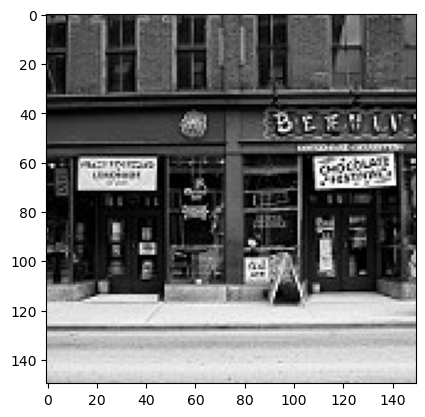

10042.jpg: 150x150


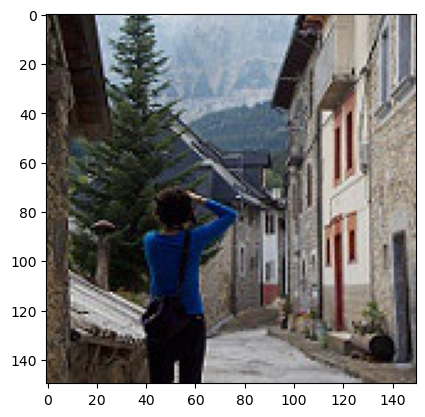

1005.jpg: 150x150


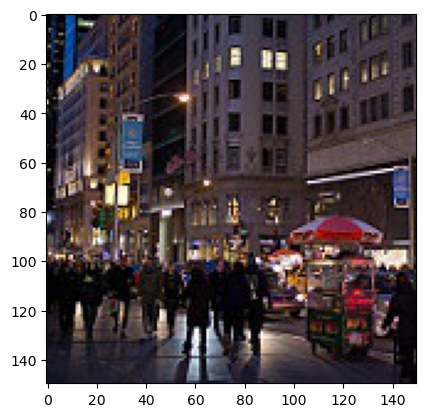

10062.jpg: 150x150


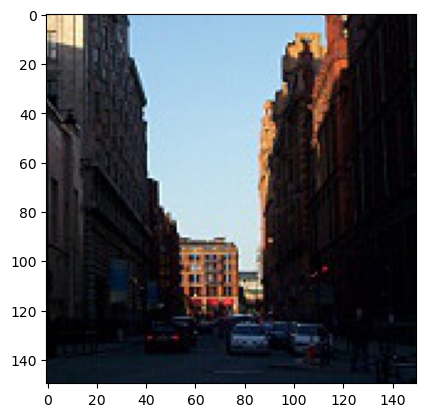

10063.jpg: 150x150


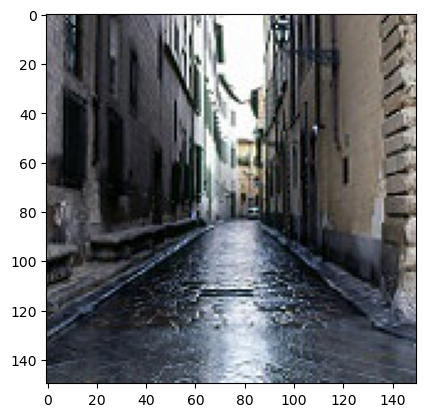

In [5]:

folder_path = r"C:\Users\usaan\Downloads\seg_train\seg_train\street"

for filename in os.listdir(folder_path)[:10]:
    # if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
        img_path = os.path.join(folder_path, filename)
        with Image.open(img_path) as img:
            width, height = img.size
            plt.imshow(img)
            print(f'{filename}: {width}x{height}')
            plt.show()

1.jpg: 150x150


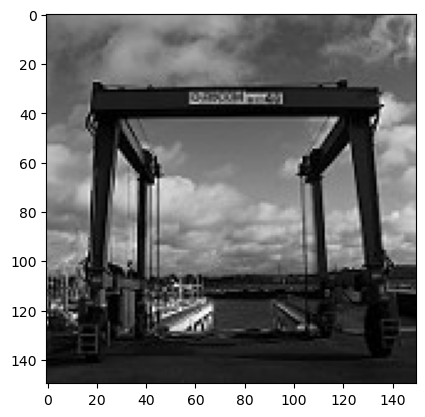

10016.jpg: 150x150


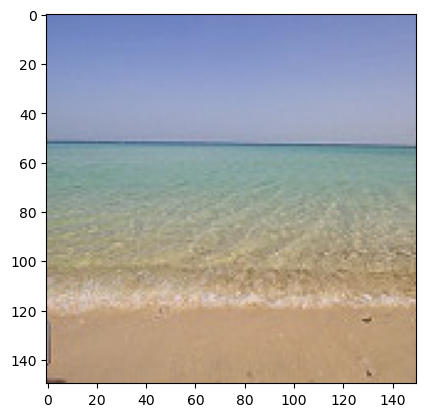

10041.jpg: 150x150


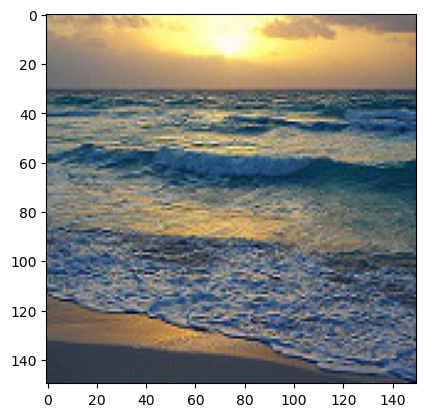

10053.jpg: 150x150


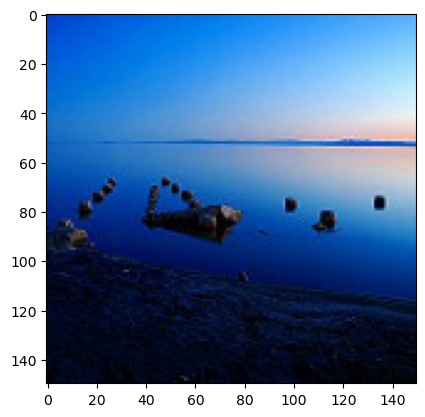

10061.jpg: 150x150


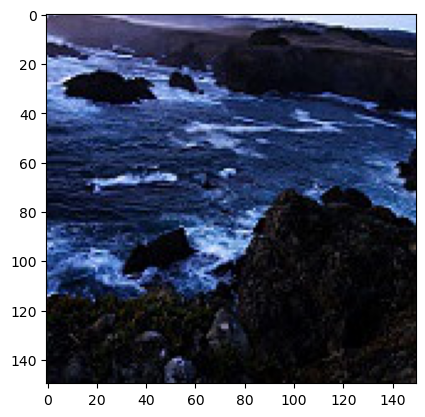

10068.jpg: 150x150


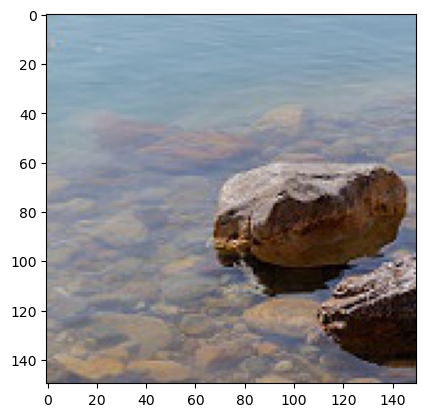

10071.jpg: 150x150


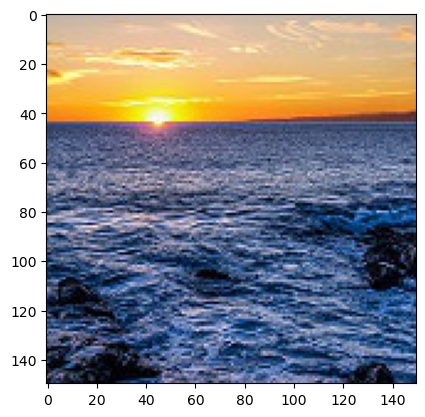

10080.jpg: 150x150


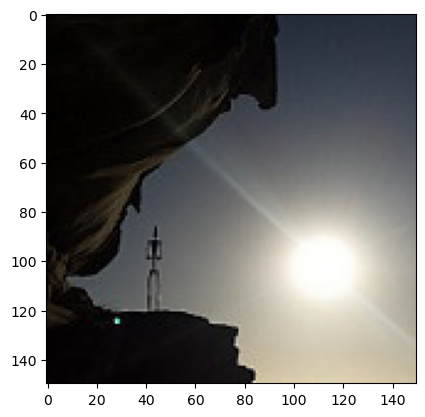

10087.jpg: 150x150


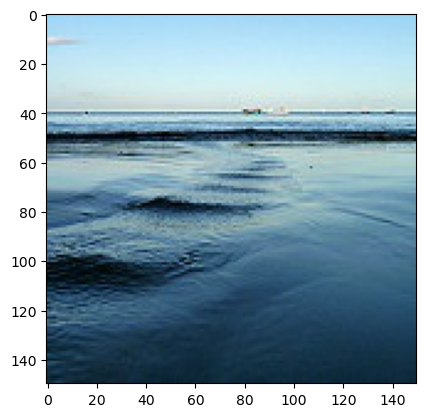

10093.jpg: 150x150


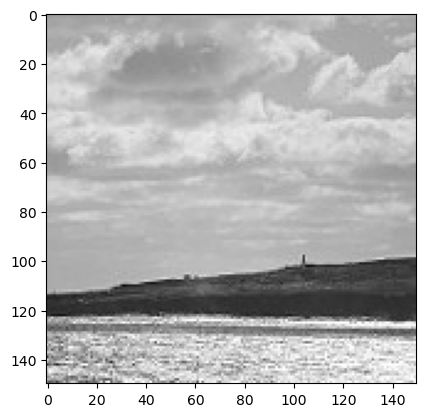

In [6]:

folder_path = r"C:\Users\usaan\Downloads\seg_train\seg_train\sea"

for filename in os.listdir(folder_path)[:10]:
    # if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
        img_path = os.path.join(folder_path, filename)
        with Image.open(img_path) as img:
            width, height = img.size
            plt.imshow(img)
            print(f'{filename}: {width}x{height}')
            plt.show()

In [22]:
train_ds=image_dataset_from_directory(train_dir,batch_size=32,image_size=(150,150))

Found 14034 files belonging to 6 classes.


In [23]:
train_ds.class_names

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

In [24]:
test_ds=image_dataset_from_directory(test_dir,batch_size=32,image_size=(150,150))

Found 3000 files belonging to 6 classes.


In [25]:
test_ds.class_names

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

In [26]:
for images, labels in train_ds.take(3):
  print(images.shape)

(32, 150, 150, 3)
(32, 150, 150, 3)
(32, 150, 150, 3)


In [27]:
for images, labels in test_ds.take(1):
  print(images.shape)

(32, 150, 150, 3)


In [40]:
model=Sequential([
    Input(shape=(150,150,3)),
    Rescaling(1/255),
    Conv2D(32,(2,2),activation="relu"),
    MaxPooling2D(),
    Conv2D(64,(2,2),activation="relu"),
    MaxPooling2D(),
    Conv2D(128,(2,2),activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.2),
    Dense(256,activation='relu'),
    Dropout(0.2),
    Dense(6,activation='softmax')
])
    

In [41]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)              │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 149, 149, 32)        │             416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 73, 73, 64)          │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 35, 35, 128)         │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 36992)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │       4,735,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 6)                   │           1,542 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,811,238 (18.35 MB)

 Trainable params: 4,811,238 (18.35 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [43]:
history = model.fit(train_ds,validation_data=(test_ds),epochs=15,batch_size=50,callbacks=EarlyStopping(patience=10))

Epoch 1/15


C:\Users\usaan\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


439/439 ━━━━━━━━━━━━━━━━━━━━ 84s 186ms/step - accuracy: 0.6064 - loss: 1.0120 - val_accuracy: 0.6187 - val_loss: 1.0340
Epoch 2/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 77s 175ms/step - accuracy: 0.7530 - loss: 0.6836 - val_accuracy: 0.7863 - val_loss: 0.5937
Epoch 3/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 76s 173ms/step - accuracy: 0.8112 - loss: 0.5267 - val_accuracy: 0.7990 - val_loss: 0.5837
Epoch 4/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 71s 162ms/step - accuracy: 0.8596 - loss: 0.4011 - val_accuracy: 0.8003 - val_loss: 0.6157
Epoch 5/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 73s 166ms/step - accuracy: 0.8997 - loss: 0.2841 - val_accuracy: 0.7897 - val_loss: 0.7275
Epoch 6/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 72s 163ms/step - accuracy: 0.9243 - loss: 0.2208 - val_accuracy: 0.8080 - val_loss: 0.6422
Epoch 7/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 74s 167ms/step - accuracy: 0.9408 - loss: 0.1716 - val_accuracy: 0.8020 - val_loss: 0.7769
Epoch 8/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 76s 174ms/step - accuracy: 0.9535 - loss: 0.1425 - val

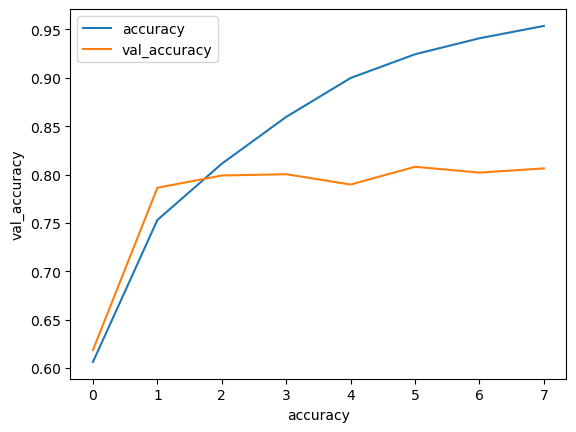

In [44]:
plt.plot(history.history["accuracy"],label="accuracy")
plt.plot(history.history["val_accuracy"],label="val_accuracy")
plt.xlabel("accuracy")
plt.ylabel("val_accuracy")
plt.legend()
plt.show()

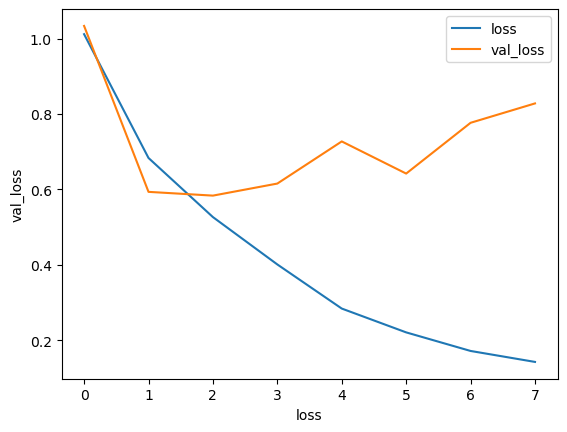

In [45]:
plt.plot(history.history["loss"],label='loss')
plt.plot(history.history["val_loss"],label='val_loss')
plt.xlabel("loss")
plt.ylabel("val_loss")
plt.legend()
plt.show()

In [46]:
model.evaluate(test_ds)

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8063 - loss: 0.8283


[0.8283365368843079, 0.8063333630561829]

In [47]:
test_img = r"C:\Users\usaan\Downloads\seg_pred\seg_pred\9976.jpg"

In [48]:
img=Image.open(test_img)

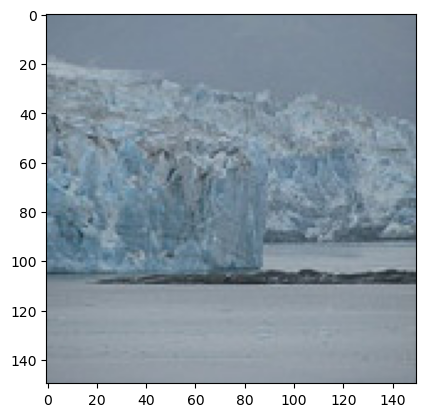

In [49]:
plt.imshow(img)

In [50]:
img.size

(150, 150)

In [51]:
from tensorflow.keras.utils import load_img,img_to_array

In [52]:
image=load_img(test_img,target_size=(150,150))

In [53]:
img_array=img_to_array(image)

In [54]:
img_array

array([[[112., 128., 144.],
        [113., 129., 145.],
        [113., 129., 145.],
        ...,
        [117., 131., 144.],
        [117., 131., 144.],
        [116., 130., 143.]],

       [[113., 129., 145.],
        [113., 129., 145.],
        [113., 129., 145.],
        ...,
        [119., 133., 146.],
        [119., 133., 146.],
        [119., 133., 146.]],

       [[113., 129., 145.],
        [113., 129., 145.],
        [113., 129., 145.],
        ...,
        [119., 132., 148.],
        [119., 133., 146.],
        [119., 133., 146.]],

       ...,

       [[134., 144., 153.],
        [135., 144., 153.],
        [135., 144., 153.],
        ...,
        [134., 144., 154.],
        [135., 144., 153.],
        [133., 142., 151.]],

       [[132., 142., 151.],
        [132., 142., 151.],
        [132., 142., 152.],
        ...,
        [133., 143., 153.],
        [134., 143., 152.],
        [130., 139., 148.]],

       [[129., 139., 149.],
        [130., 140., 150.],
        [130., 1

In [55]:
img_arr = np.expand_dims(img_array,axis=0)

In [56]:
img_arr

array([[[[112., 128., 144.],
         [113., 129., 145.],
         [113., 129., 145.],
         ...,
         [117., 131., 144.],
         [117., 131., 144.],
         [116., 130., 143.]],

        [[113., 129., 145.],
         [113., 129., 145.],
         [113., 129., 145.],
         ...,
         [119., 133., 146.],
         [119., 133., 146.],
         [119., 133., 146.]],

        [[113., 129., 145.],
         [113., 129., 145.],
         [113., 129., 145.],
         ...,
         [119., 132., 148.],
         [119., 133., 146.],
         [119., 133., 146.]],

        ...,

        [[134., 144., 153.],
         [135., 144., 153.],
         [135., 144., 153.],
         ...,
         [134., 144., 154.],
         [135., 144., 153.],
         [133., 142., 151.]],

        [[132., 142., 151.],
         [132., 142., 151.],
         [132., 142., 152.],
         ...,
         [133., 143., 153.],
         [134., 143., 152.],
         [130., 139., 148.]],

        [[129., 139., 149.],
       

In [57]:
pred = model.predict(img_arr)
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


array([[6.7345274e-05, 9.5290670e-05, 8.7835473e-01, 2.5641087e-02,
        9.5786378e-02, 5.5252462e-05]], dtype=float32)

In [76]:
index = np.argmax(pred,axis=1,)[0]
index

np.int64(5)

In [77]:
X[index]

'street'

In [ ]:
"C:\Users\usaan\Downloads\seg_pred\seg_pred\9976.jpg"

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted Label: street


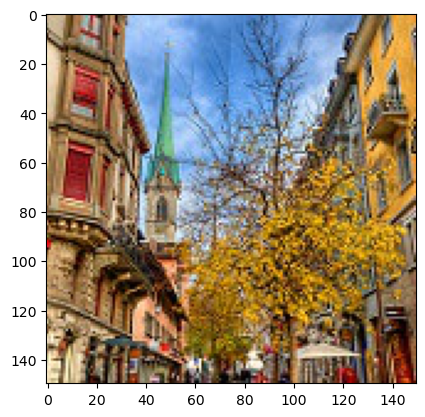

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Predicted Label: mountain


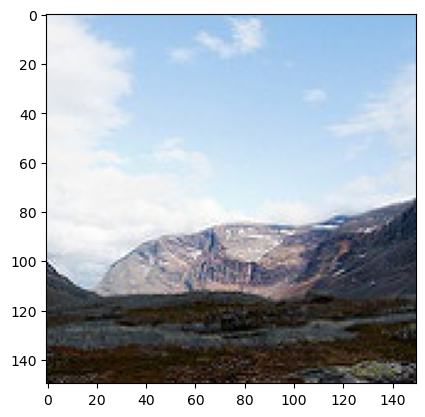

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted Label: street


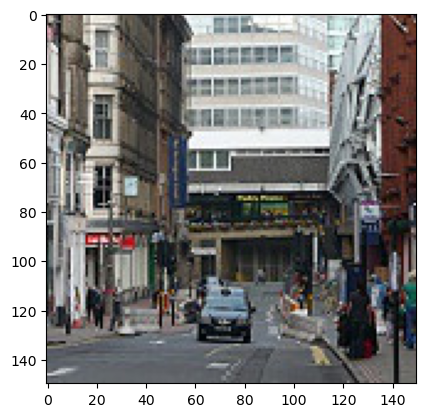

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Predicted Label: mountain


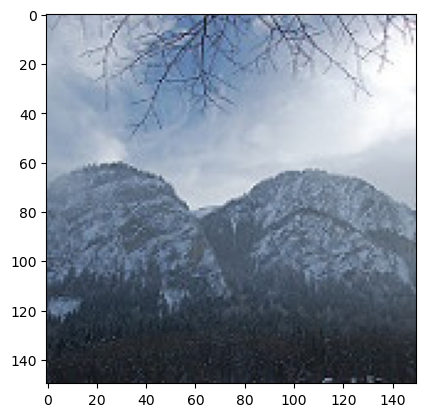

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Predicted Label: mountain


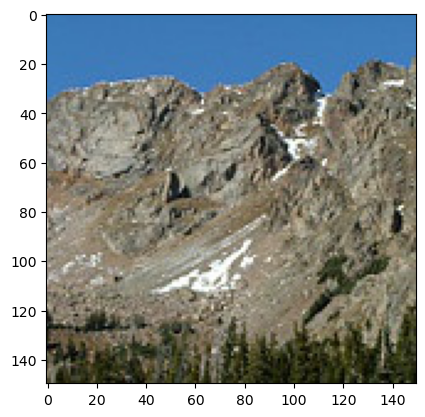

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted Label: forest


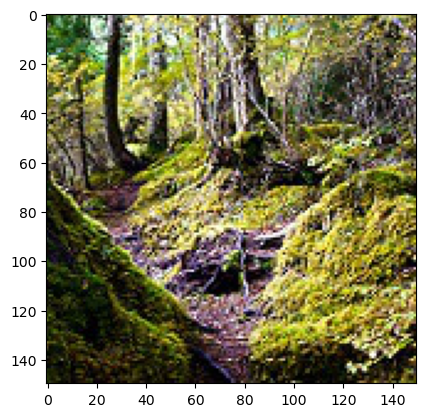

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Predicted Label: sea


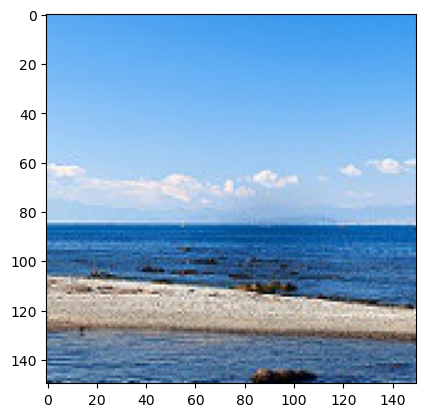

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Predicted Label: glacier


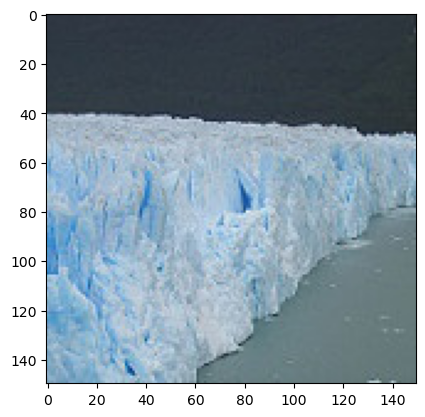

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted Label: sea


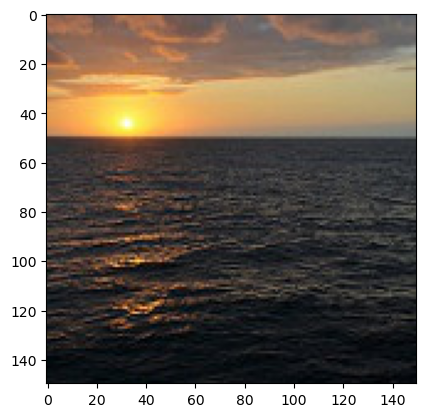

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Predicted Label: street


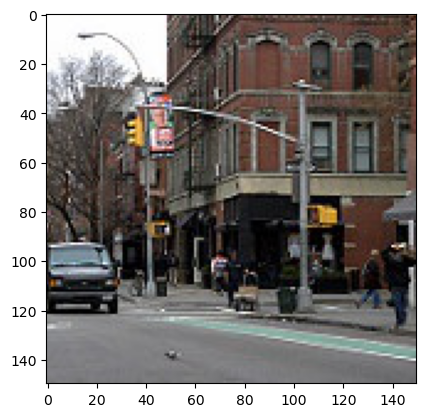

In [82]:
folder_path = r"C:\Users\usaan\Downloads\seg_pred\seg_pred"

for filename in os.listdir(folder_path)[:10]:
        img = os.path.join(folder_path, filename)
        image=load_img(img,target_size=(150,150))
        img_array=img_to_array(image)
        img_arr = np.expand_dims(img_array,axis=0)
        pred = model.predict(img_arr)
        index = np.argmax(pred,axis=1,)[0]
            
        plt.imshow(Image.open(img))
        print(f'Predicted Label: {X[index]}')
        plt.show()

In [63]:
img = Image.open(r"C:\Users\usaan\Downloads\seg_pred\seg_pred\10004.jpg")

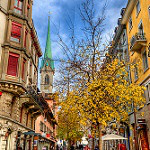

In [68]:
load_img(r"C:\Users\usaan\Downloads\seg_pred\seg_pred\10004.jpg")

In [66]:
img_to_array(img)

array([[[175., 152., 120.],
        [203., 182., 151.],
        [202., 179., 145.],
        ...,
        [242., 179.,  82.],
        [226., 155.,  73.],
        [236., 162.,  89.]],

       [[197., 172., 141.],
        [215., 192., 161.],
        [209., 184., 153.],
        ...,
        [237., 167.,  69.],
        [243., 164.,  72.],
        [235., 149.,  62.]],

       [[195., 170., 139.],
        [201., 177., 149.],
        [214., 191., 160.],
        ...,
        [239., 166.,  64.],
        [242., 159.,  57.],
        [242., 153.,  51.]],

       ...,

       [[255., 237., 201.],
        [245., 226., 184.],
        [255., 238., 192.],
        ...,
        [113.,   2.,   0.],
        [ 65.,   0.,   0.],
        [157.,  82.,  76.]],

       [[249., 231., 193.],
        [225., 206., 164.],
        [185., 168., 122.],
        ...,
        [141.,  32.,   3.],
        [ 70.,   0.,   0.],
        [154.,  83.,  65.]],

       [[251., 233., 195.],
        [244., 225., 182.],
        [215., 1

In [ ]:
model.save("intel_images.keras")